In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra
using Random

[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a partially installed environment. Try `Pkg.instantiate()`
│      to ensure all packages in the environment are installed.
│    - Or, if you have LatticeQCD checked out for development and have
│      added Plots as a dependency but haven't updated your primary
│      environment's manifest file, try `Pkg.resolve()`.
│    - Otherwise you may need to report an issue with LatticeQCD
│    Stacktrace:
│      [1] macro expansion
│        @ .\loading.jl:1839 [inlined]
│      [2] macro expansion
│        @ .\lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base .\loading.jl:1816
│      [4] #invoke_in_world#3


In [2]:
NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[0.001220619994521516 - 0.0031594695261446984im 0.0003171647621523759 - 0.0003731882061158866im … 0.0029516426340153875 + 0.00018050997973047104im -0.003758613833609558 - 0.0018649321618784045im; 0.0028896857523980947 - 0.0025714929985568087im 0.0008258377730467908 + 0.002255417878368361im … 0.00042626149366894144 - 0.001232382624041703im -0.001246420937718123 + 0.004953586084545698im; -0.00047567463109395155 - 0.0003830158546267542im -0.0025242762169760025 - 0.0010638555560790312im … 0.001947324942008472 - 0.00399291127588589im -0.0023531932793071455 - 0.0019939427741725293im;;; 0.0015245486623838836 - 0.0028352076376675526im 0.0035658560704566393 + 0.00204662015151095im … 0.00132692757104829 - 0.005593945470586477im 0.0033061685917607697 - 0.006988080254203579im; -0.0023070281319073774 + 0.0036832774694661825im 0.002813188835515505 - 0.0012710104164989147im … -0.0001227066785598647 - 0.0013199449904034253im 0.

In [3]:
function calc_action(gauge_action,U,p)
    NC = U[1].NC
    Sg = -evaluate_GaugeAction(gauge_action,U)/NC #evaluate_Gauge_action(gauge_action,U) = tr(evaluate_Gaugeaction_untraced(gauge_action,U))
    Sp = p*p/2
    S = Sp + Sg
    return real(S)
end

function MDstep!(gauge_action,U,p,MDsteps,Dim,Uold,temp1,temp2)
    Δτ = 1.0/MDsteps
    gauss_distribution!(p)
    Sold = calc_action(gauge_action,U,p)
    substitute_U!(Uold,U)

    for itrj=1:MDsteps
        U_update!(U,p,0.5,Δτ,Dim,gauge_action)

        P_update!(U,p,1.0,Δτ,Dim,gauge_action,temp1,temp2)

        U_update!(U,p,0.5,Δτ,Dim,gauge_action)
    end
    Snew = calc_action(gauge_action,U,p)
    println("Sold = $Sold, Snew = $Snew")
    println("Snew - Sold = $(Snew-Sold)")
    ratio = min(1,exp(-Snew+Sold))
    if rand() > ratio
        substitute_U!(U,Uold)
        return false
    else
        return true
    end
end

function U_update!(U,p,ϵ,Δτ,Dim,gauge_action)
    temps = get_temporary_gaugefields(gauge_action)
    temp1 = temps[1]
    temp2 = temps[2]
    expU = temps[3]
    W = temps[4]

    for μ=1:Dim
        exptU!(expU,ϵ*Δτ,p[μ],[temp1,temp2])
        mul!(W,expU,U[μ])
        substitute_U!(U[μ],W)
        
    end
end

function P_update!(U,p,ϵ,Δτ,Dim,gauge_action,temp1,temp2) # p -> p +factor*U*dSdUμ
    NC = U[1].NC
    temp = temp1
    dSdUμ = temp2
    factor =  -ϵ*Δτ/(NC)

    for μ=1:Dim
        calc_dSdUμ!(dSdUμ,gauge_action,μ,U)
        mul!(temp,U[μ],dSdUμ) # U*dSdUμ
        Traceless_antihermitian_add!(p[μ],factor,temp)
    end
end


function HMC_test_4D(NX,NY,NZ,NT,NC,β)
    Dim = 4
    Nwing = 0

    Random.seed!(123)


    U = Initialize_Gaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot",randomnumber="Reproducible")
    #"Reproducible"
    println(typeof(U))

    temp1 = similar(U[1])
    temp2 = similar(U[1])

    if Dim == 4
        comb = 6 #4*3/2
    elseif Dim == 3
        comb = 3
    elseif Dim == 2
        comb = 1
    else
        error("dimension $Dim is not supported")
    end

    factor = 1/(comb*U[1].NV*U[1].NC)


    @time plaq_t = calculate_Plaquette(U,temp1,temp2)*factor
    println("0 plaq_t = $plaq_t")
    poly = calculate_Polyakov_loop(U,temp1,temp2) 
    println("0 polyakov loop = $(real(poly)) $(imag(poly))")

    gauge_action = GaugeAction(U)
    plaqloop = make_loops_fromname("plaquette")
    append!(plaqloop,plaqloop')
    β = β/2
    push!(gauge_action,β,plaqloop)
    
    #show(gauge_action)

    p = initialize_TA_Gaugefields(U) #This is a traceless-antihermitian gauge fields. This has NC^2-1 real coefficients. 
    Uold = similar(U)
    substitute_U!(Uold,U)
    MDsteps = 500
    temp1 = similar(U[1])
    temp2 = similar(U[1])
    comb = 6
    factor = 1/(comb*U[1].NV*U[1].NC)
    numaccepted = 0

    numtrj = 10
    for itrj = 1:numtrj
        t = @timed begin
            accepted = MDstep!(gauge_action,U,p,MDsteps,Dim,Uold,temp1,temp2)
        end
        if get_myrank(U) == 0
            println("elapsed time for MDsteps: $(t.time) [s]")
        end
        numaccepted += ifelse(accepted,1,0)

        #plaq_t = calculate_Plaquette(U,temp1,temp2)*factor
        #println("$itrj plaq_t = $plaq_t")
        
        if itrj % 10 == 0
            @time plaq_t = calculate_Plaquette(U,temp1,temp2)*factor
            println("$itrj plaq_t = $plaq_t")
            poly = calculate_Polyakov_loop(U,temp1,temp2) 
            println("$itrj polyakov loop = $(real(poly)) $(imag(poly))")
            println("acceptance ratio ",numaccepted/itrj)
        end
    end
    return plaq_t,numaccepted/numtrj

end


function main()
    β = 5.7
    NX = 8
    NY = 8
    NZ = 8
    NT = 8
    NC = 3
    HMC_test_4D(NX,NY,NZ,NT,NC,β)
end
main()

Vector{Gaugefields.AbstractGaugefields_module.Gaugefields_4D_nowing{3}}
  0.396823 seconds (224.54 k allocations: 14.730 MiB, 99.34% compilation time)
0 plaq_t = 0.0005345347610403964
0 polyakov loop = -0.0004671782988308305 -0.002497235753135672
Sold = 65131.610045865375, Snew = 65131.6444455993
Snew - Sold = 0.03439973392232787
elapsed time for MDsteps: 8.9127602 [s]
Sold = 28109.59745721965, Snew = 28109.61727404134
Snew - Sold = 0.019816821688436903
elapsed time for MDsteps: 7.7187163 [s]
Sold = 15599.359193940982, Snew = 15599.367924467086
Snew - Sold = 0.008730526104045566
elapsed time for MDsteps: 7.707466 [s]
Sold = 9547.89577064188, Snew = 9547.899747160525
Snew - Sold = 0.003976518644776661
elapsed time for MDsteps: 7.7337409 [s]
Sold = 5701.397112705396, Snew = 5701.399108885678
Snew - Sold = 0.001996180282731075
elapsed time for MDsteps: 7.7156225 [s]
Sold = 3078.635625277275, Snew = 3078.6377233361927
Snew - Sold = 0.0020980589179089293
elapsed time for MDsteps: 7.680291 [

(0.492541676519902, 1.0)

In [4]:
params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.141139
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 3
params["mass"] = 0.6

D = Dirac_operator(U,x,params)
y=similar(x)
gauss_distribution_fermion!(x)
mul!(y,D,x)
den=norm2(y)
target=x/den
input=y/den

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-1.025013211961888e-5 - 4.252333754698015e-6im 7.392148166263767e-6 - 4.930893771738824e-7im … -1.6583760151016226e-6 - 1.5481806761876123e-6im -1.6714833290654074e-6 - 5.782194198160762e-6im; 3.421575530850493e-6 - 1.1703391793655233e-6im 3.100657486636191e-6 - 4.747684506296793e-6im … 4.75878341598326e-6 - 6.796277019404296e-6im 9.585644232640427e-6 - 1.705884811839553e-7im; 6.119542109644198e-6 + 4.6611922660683175e-6im -7.119774916201922e-7 - 6.395347855834528e-6im … -1.6887464954441833e-5 + 4.396920647844337e-6im -8.541173793723155e-6 + 9.007401414480232e-6im;;; 5.833782035618535e-6 - 6.993515662260668e-6im -3.4903955020534576e-6 + 4.049242919465152e-6im … -3.513781636643957e-6 - 7.631844292975858e-6im -7.194326819637836e-6 + 1.0719041370746481e-5im; -6.129197932926189e-6 + 1.00254032649282e-5im 1.732787078776125e-5 + 4.9321143609757855e-6im … -4.568150415925572e-6 - 6.080933379018237e-6im 1.06226317789176

In [5]:
P=Onestep()
hop=Hopping_operator(U,P)
W=Generate_weight(hop)

9-element Vector{Spin_matrix}:
 [0.3538749382586065 + 0.37203528196558056im -0.5643144732873797 + 0.3965061910496685im -0.5355342175473748 + 0.7294088806561344im 0.20467490302437102 + 1.953625841377983im; -1.1081064126441484 + 0.4278295686504509im -0.5132036827809551 - 0.06596462184634329im -0.2944766396179594 - 1.7240464614941338im 0.147348295654807 - 0.3185966458468654im; 0.08179131895267593 - 0.07133373354531546im 0.6928581006816782 + 0.7990369030732024im 0.633931762144853 + 0.04854349482974047im 1.0514775140222505 - 0.14354238648466122im; -0.9155541651808299 + 0.6847090478446349im -0.1727755790587377 - 0.4137477974735243im -0.004948839448091562 + 0.5834609964648599im -1.3070933231401143 - 0.2659208987868637im]
 [1.1750603823231427 + 0.0686684908366392im -0.8396021675517943 + 0.6740390709508274im -0.9508375391267162 + 1.727442100050329im -0.4052473924549449 + 0.25349828539090463im; 1.608473156121957 - 0.700422104758116im 0.6381025237093385 - 1.8593039774535745im 0.3820724132843811 +

In [6]:
layer1=PTC_Layer(hop,W)

PTC_Layer(Spin_matrix[[0.3538749382586065 + 0.37203528196558056im -0.5643144732873797 + 0.3965061910496685im -0.5355342175473748 + 0.7294088806561344im 0.20467490302437102 + 1.953625841377983im; -1.1081064126441484 + 0.4278295686504509im -0.5132036827809551 - 0.06596462184634329im -0.2944766396179594 - 1.7240464614941338im 0.147348295654807 - 0.3185966458468654im; 0.08179131895267593 - 0.07133373354531546im 0.6928581006816782 + 0.7990369030732024im 0.633931762144853 + 0.04854349482974047im 1.0514775140222505 - 0.14354238648466122im; -0.9155541651808299 + 0.6847090478446349im -0.1727755790587377 - 0.4137477974735243im -0.004948839448091562 + 0.5834609964648599im -1.3070933231401143 - 0.2659208987868637im], [1.1750603823231427 + 0.0686684908366392im -0.8396021675517943 + 0.6740390709508274im -0.9508375391267162 + 1.727442100050329im -0.4052473924549449 + 0.25349828539090463im; 1.608473156121957 - 0.700422104758116im 0.6381025237093385 - 1.8593039774535745im 0.3820724132843811 + 0.1201111

In [7]:
opt=Adam()
opt.α=0.05

0.05

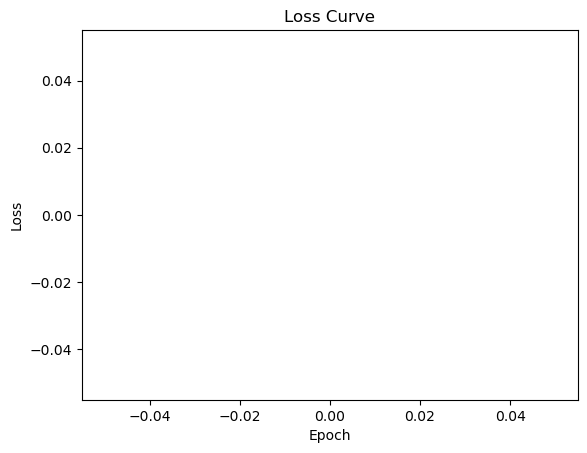

Epoch: 1, Loss: 9.072870098328562e6 + 0.0im
Epoch: 2, Loss: 2.105151684746599e6 + 0.0im
Epoch: 3, Loss: 2.0176114732798357e6 + 0.0im
Epoch: 4, Loss: 1.9264939553915479e6 + 0.0im
Epoch: 5, Loss: 1.8093512231701072e6 + 0.0im
Epoch: 6, Loss: 1.6773309620802102e6 + 0.0im
Epoch: 7, Loss: 1.5506958377094467e6 + 0.0im
Epoch: 8, Loss: 1.421329973229289e6 + 0.0im
Epoch: 9, Loss: 1.278402408084318e6 + 0.0im
Epoch: 10, Loss: 1.1483594726967928e6 + 0.0im
Epoch: 11, Loss: 1.0354372223385755e6 + 0.0im
Epoch: 12, Loss: 924546.9612917467 + 0.0im
Epoch: 13, Loss: 816540.733297951 + 0.0im
Epoch: 14, Loss: 710661.1996503277 + 0.0im
Epoch: 15, Loss: 628619.683986796 + 0.0im
Epoch: 16, Loss: 554185.4236990317 + 0.0im
Epoch: 17, Loss: 486487.8550429655 + 0.0im
Epoch: 18, Loss: 431205.12849944085 + 0.0im
Epoch: 19, Loss: 372184.273367623 + 0.0im
Epoch: 20, Loss: 328156.5370768291 + 0.0im
Epoch: 21, Loss: 289258.01108058804 + 0.0im
Epoch: 22, Loss: 254289.45234776748 + 0.0im
Epoch: 23, Loss: 225502.7567880855

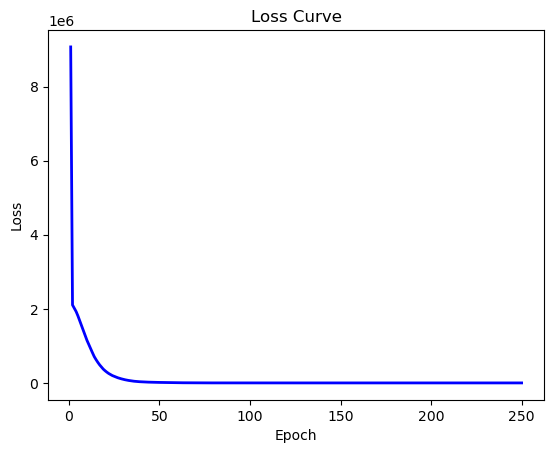

In [8]:
doubletrain(opt,[layer1],x,t,D,epochs=250)

In [9]:
f=deepcopy(x)

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[0.8854766745636881 + 0.128994094137453im -0.82143673574025 - 1.3094473377144897im … -0.34396467283492144 - 2.10878599335885im 0.24293884292791007 - 0.4030113656797226im; 0.9839772043230808 - 0.703357674295836im -1.2578189335063596 - 1.2368749393627703im … -1.519303561334565 - 0.7292256858597151im 1.6904323298252053 - 0.46761501483479806im; 0.13005797425000024 + 1.2868803241538989im -0.21296471317164928 + 0.25184057981430347im … -0.2401991140460999 - 0.003384470815409364im 0.6406722927999523 - 0.45292647272078im;;; 1.6870436356794263 + 0.6310172104767597im -0.5242379297034039 + 1.0678202165464818im … 0.26846346724244924 - 0.6956214999922906im 0.6509316127195082 - 0.397443762571133im; 0.24784615082052852 - 0.3145314310023708im -0.28161748990866725 - 1.3678193856027618im … -0.6632944436487581 - 0.3182965537249743im -0.4491119706823556 + 0.28646739805648536im; -0.17346760524354454 - 0.5070604967093478im 0.541158556

In [10]:
b=similar(x)
b[1,1,1,1,1,1]=1.0

1.0

In [11]:
norm2(D*x-b)

129472.15898868653 + 0.0im

In [12]:
norm2(layer1(D*x)-layer1(b))

0.0018252034309656088 + 0.0im

In [13]:
y=layer1(D*x)
u=layer1(b)

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-0.0001386135651947954 - 1.2100816827618967e-5im 2.0721311002819838e-5 + 1.1809384690284193e-7im … 0.0 + 0.0im 8.143730041230864e-6 + 1.566527387406122e-5im; 0.0 + 0.0im -2.837872844903954e-7 + 6.957002234522818e-6im … 0.0 + 0.0im -1.477196619710668e-5 - 6.5180888744820985e-6im; 0.0 + 0.0im 3.130431147341723e-6 - 1.9418101961099072e-5im … 0.0 + 0.0im -1.262034861198207e-5 + 2.5527201806059566e-5im;;; -7.971932087230541e-7 + 1.3717106667687106e-5im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 1.2629982328778581e-5 + 4.174088142226025e-6im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 1.3649034327428716e-5 + 3.92515805908928e-6im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0

In [14]:
gmres(x,D,b)

Converged at 2-9-th step. eps: 6.367083986324031e-11


In [15]:
gmres(y,D,u)

Converged at 2-14-th step. eps: 4.837897650186357e-11


In [16]:
norm2(D*x-b)

6.367083986326096e-11 + 0.0im

In [17]:
y=y/norm2(y)
u=u/norm2(u)

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-5380.387241597921 - 469.7020842133216im 804.3128909647338 + 4.583899319625367im … 0.0 + 0.0im 316.1048570627304 + 608.0590999134113im; 0.0 + 0.0im -11.015411678172276 + 270.04114647647964im … 0.0 + 0.0im -573.3847069623803 - 253.00440235110284im; 0.0 + 0.0im 121.50998195731107 - 753.7278757726367im … 0.0 + 0.0im -489.8680916330398 + 990.8570688446251im;;; -30.94363934203951 + 532.4395603182468im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 490.24203141929576 + 162.02029400352893im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 529.7972824826161 + 152.357890172586im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.

In [18]:
norm2(D*y-u)

6.774582351965884e6 + 0.0im

In [19]:
# pregmres(f,D,b,layer1)